Run IMSTE on MNIST, Fashion-MNIST, and Kuzushiji-MNIST. For each dataset, the gallery first shows a grid of sample images with one column per class and a configurable number of rows. It standardizes a stratified sample and fits IMSTE directly to the flattened image features. Choose the MST builder with `MST_METHOD`: FAMST is the approximate default, and Prim builds the exact graph. A following cell fits UMAP to those same standardized samples and compares IMSTE and UMAP side by side, with each method's runtime in its title. The summary reports the sample and feature counts and selected builder.

Remote datasets download on first use and are cached. Set `MAX_SAMPLES` or `N_EPOCHS` lower for a faster run. `N_MSTS`, `NEGATIVE_RATIO`, and `FAMST_MAX_NEIGHBORS` configure the graph and negative sampling; their defaults are 4, 1, and 15.


In [1]:
%load_ext autoreload
%autoreload 2

%config InlineBackend.figure_format = 'retina'

from pathlib import Path
import sys

repo_root = next(
    (path for path in (Path.cwd(), *Path.cwd().parents)
     if (path / "notebooks" / "src" / "high_dim_mst_gallery.py").is_file()),
    None,
)
if repo_root is not None:
    sys.path.insert(0, str(repo_root / "notebooks" / "src"))
    sys.path.insert(0, str(repo_root))

Loading MNIST (28×28) ...


  10,000 samples × 784 features; 10 classes


Loading Fashion-MNIST (28×28) ...


  10,000 samples × 784 features; 10 classes


Loading Kuzushiji-MNIST (28×28) ...


  10,000 samples × 784 features; 10 classes


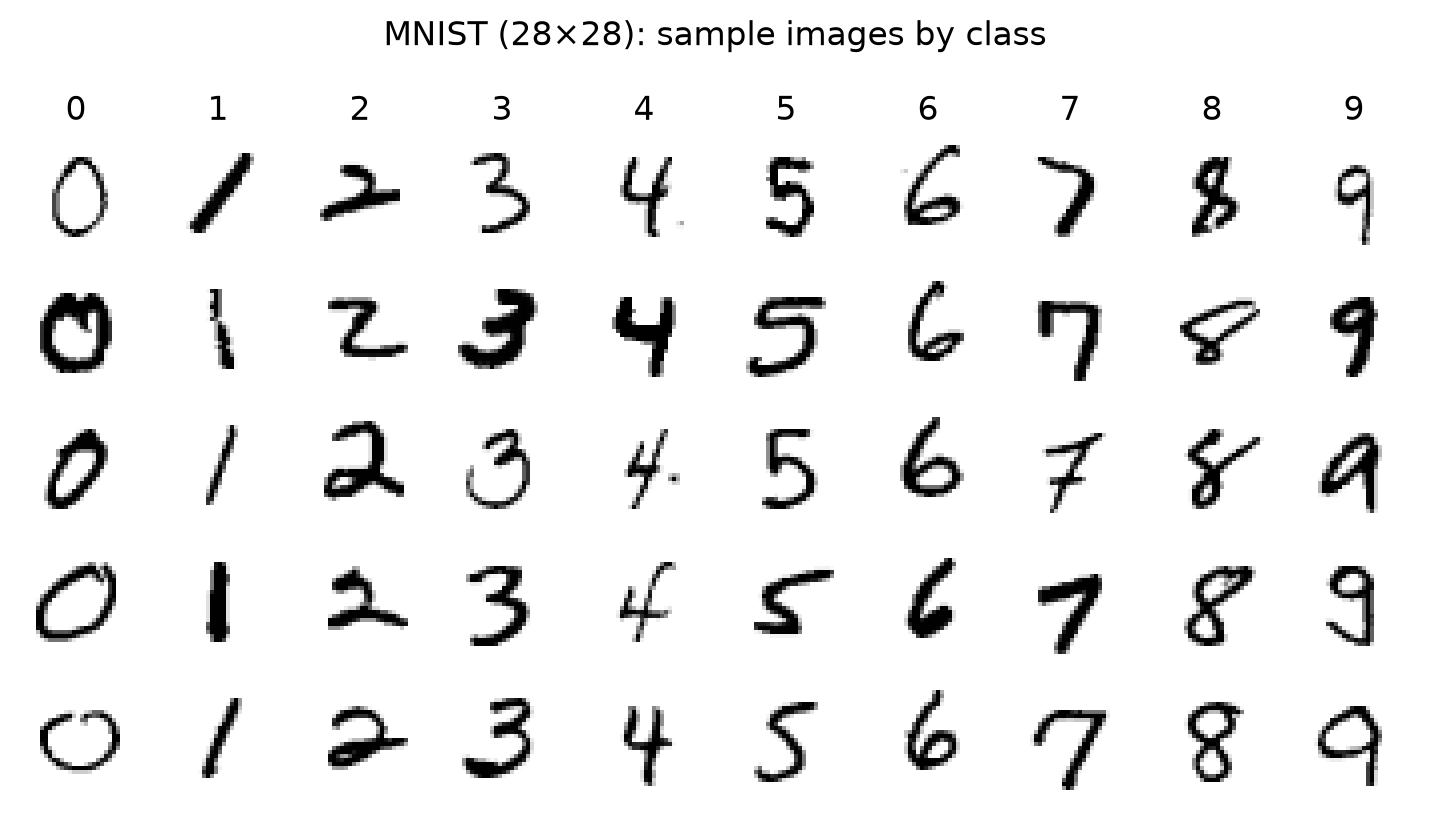

Fitting MNIST (28×28) with FAMST on auto ...


  pipeline completed in 13.24 seconds


  standardized IMSTE input: 10,000 samples × 784 features


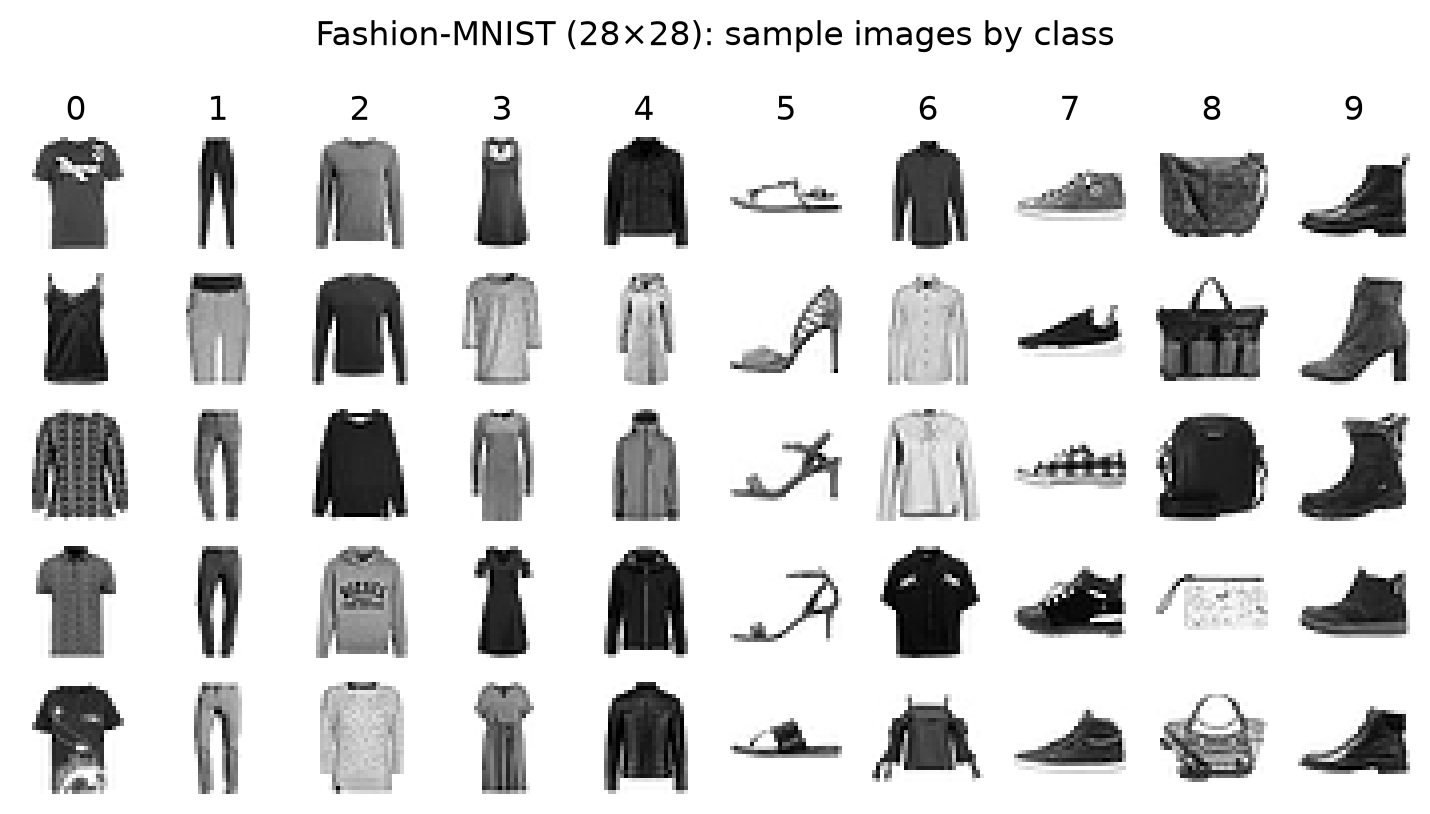

Fitting Fashion-MNIST (28×28) with FAMST on auto ...


  pipeline completed in 3.28 seconds


  standardized IMSTE input: 10,000 samples × 784 features


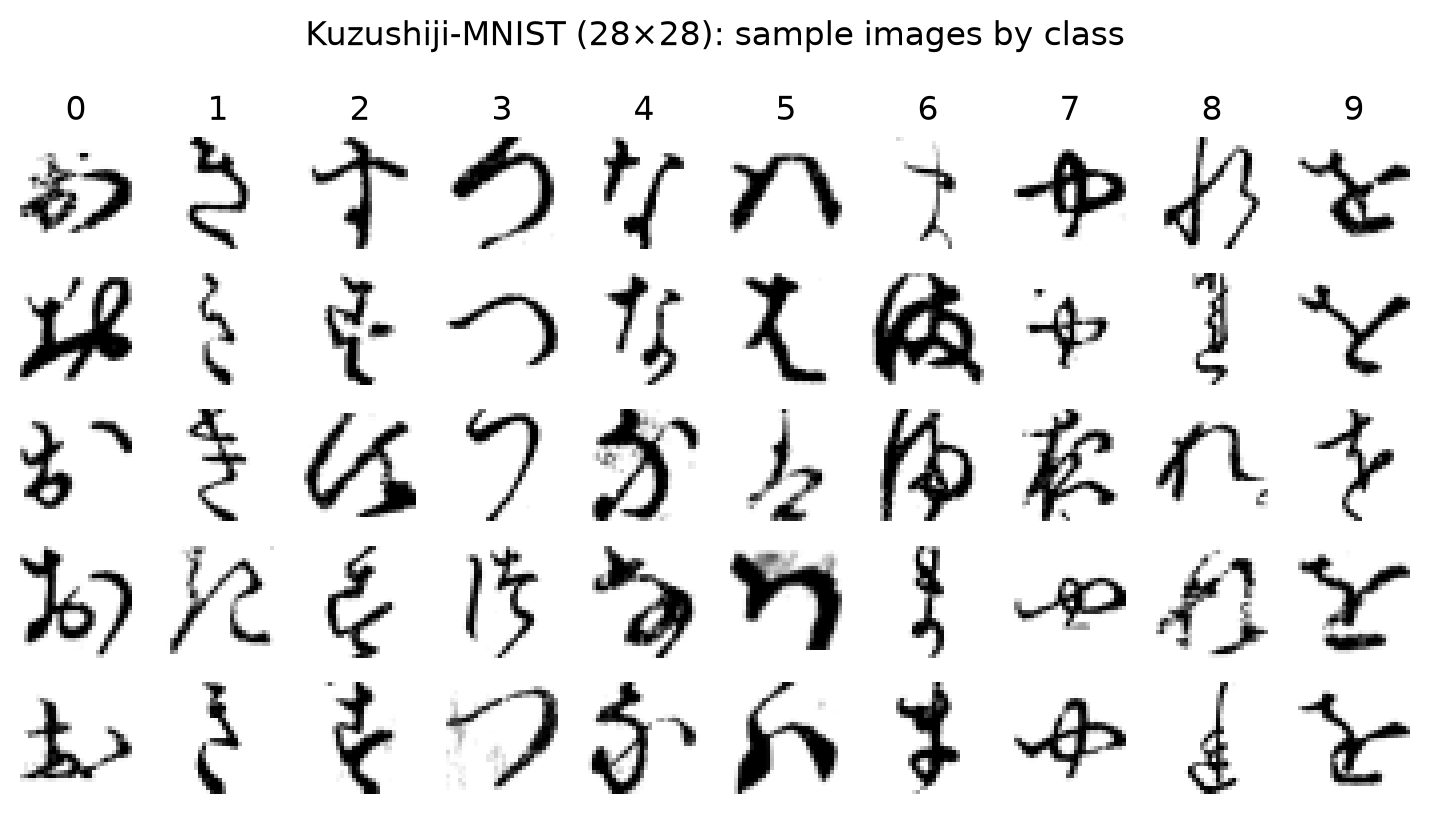

Fitting Kuzushiji-MNIST (28×28) with FAMST on auto ...


  pipeline completed in 3.90 seconds


  standardized IMSTE input: 10,000 samples × 784 features


,dataset,samples,input_features,features,classes,n_msts,mst_method,mst_max_neighbors,n_epochs,negative_ratio,lambda_rep,unique_graph_edges,seconds,device
0,MNIST (28×28),10000,784,784,10,4,famst,30,1000,1,0.5,39996,13.240330,cpu
1,Fashion-MNIST (28×28),10000,784,784,10,4,famst,30,1000,1,0.5,39996,3.276865,cpu
2,Kuzushiji-MNIST (28×28),10000,784,784,10,4,famst,30,1000,1,0.5,39996,3.902278,cpu


In [2]:
from high_dim_mst_gallery import run_high_dim_mst_gallery

# Dataset
MAX_SAMPLES = 10000
SAMPLE_PLOT_ROWS = 5

#----
# Graph construction
MST_METHOD = "famst"  # choose "prim" for the exact graph famst
N_MSTS = 4
NEGATIVE_RATIO = 1
FAMST_MAX_NEIGHBORS = 30

gallery = run_high_dim_mst_gallery(
    max_samples=MAX_SAMPLES,
    sample_plot_rows=SAMPLE_PLOT_ROWS,
    n_msts=N_MSTS,
    negative_ratio=NEGATIVE_RATIO,
    mst_max_neighbors=FAMST_MAX_NEIGHBORS,
    mst_method=MST_METHOD,
    n_epochs=1000,
    plot_embeddings=False,  # Compare IMSTE and UMAP together in the next cell.
)
gallery["summary"]


## Side-by-side IMSTE and UMAP embeddings

Fit UMAP to the same standardized samples used for IMSTE, then compare each dataset in a shared figure. Both panels use the same class labels and report their fit times in the titles.


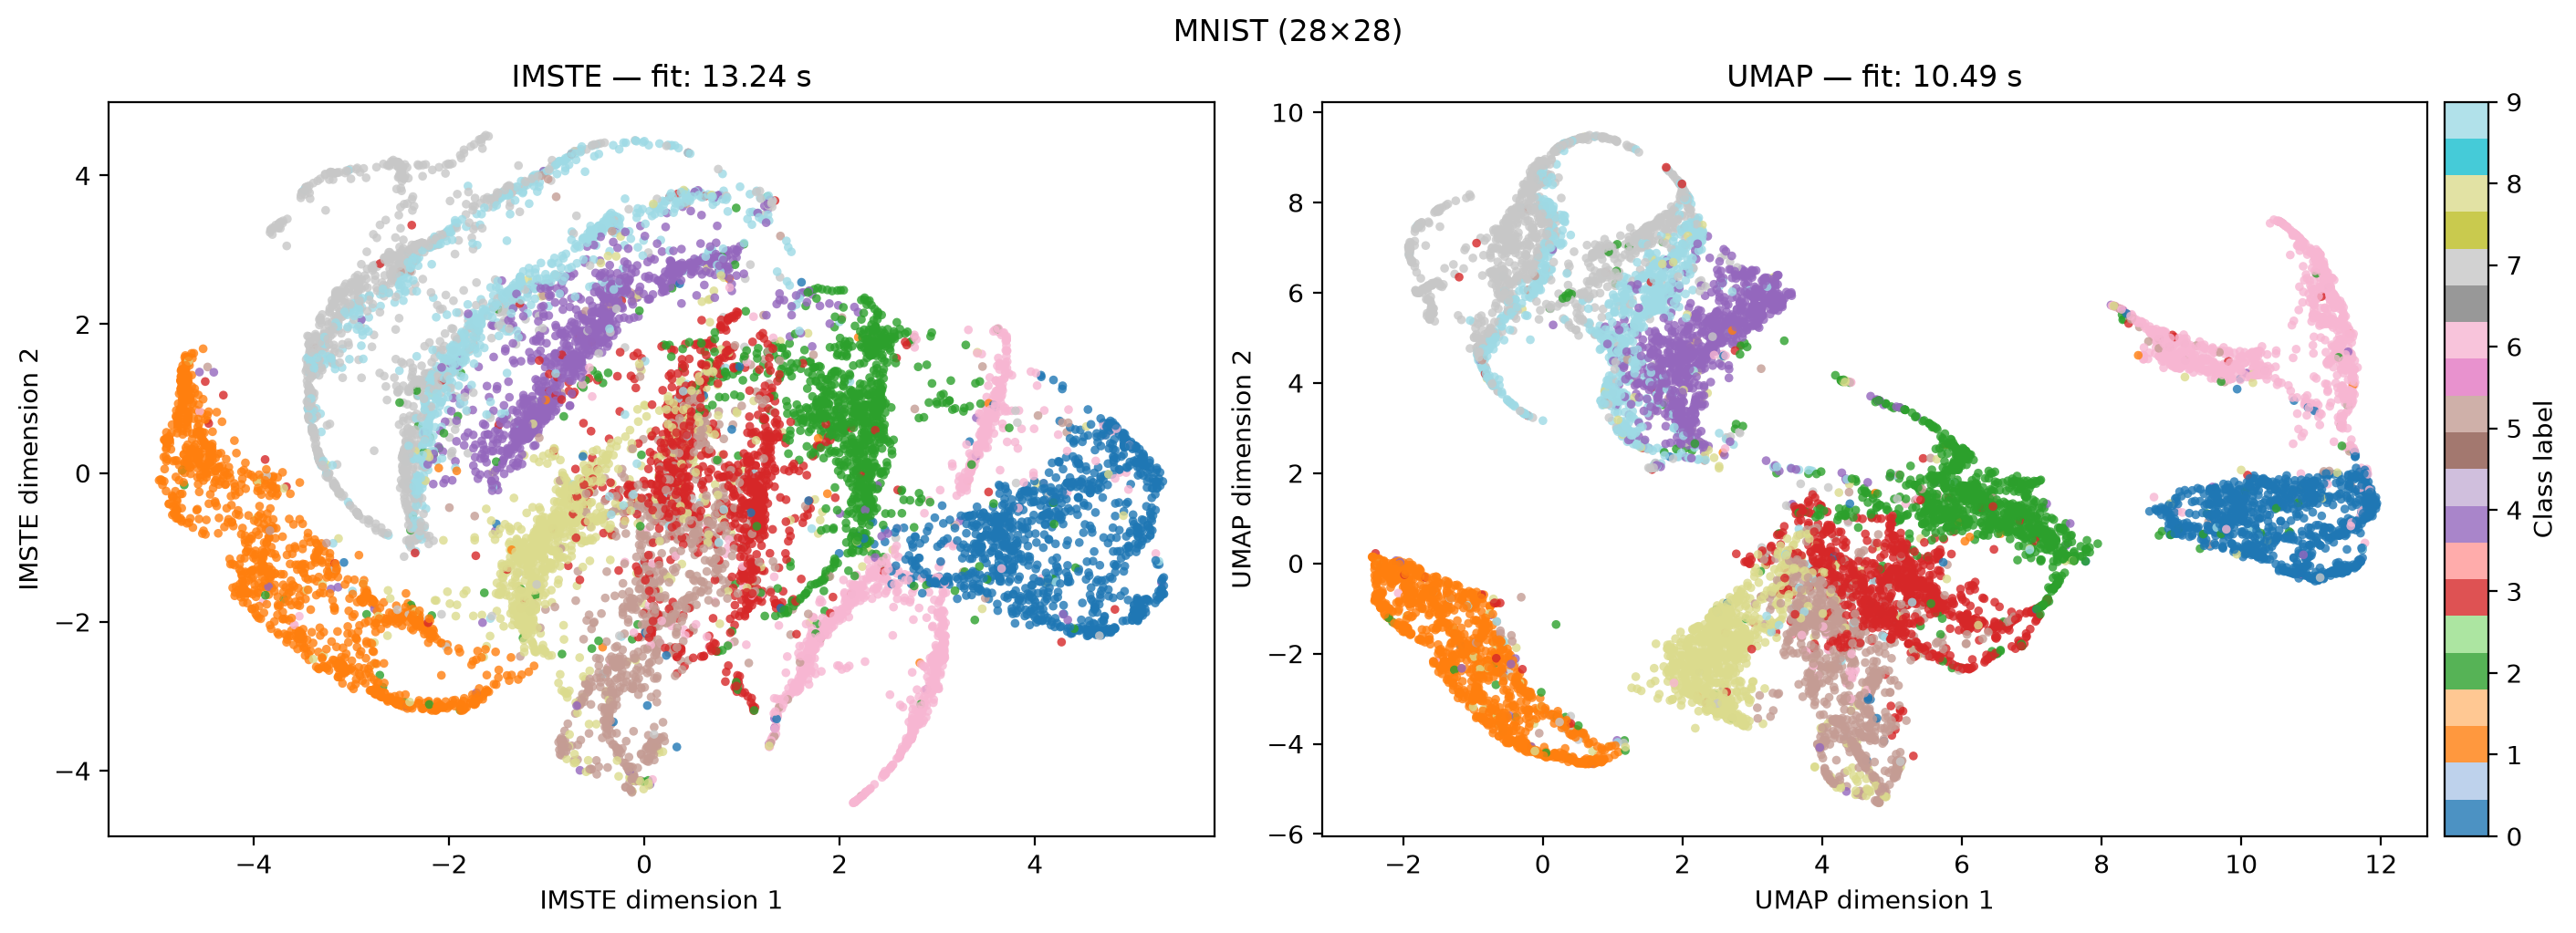

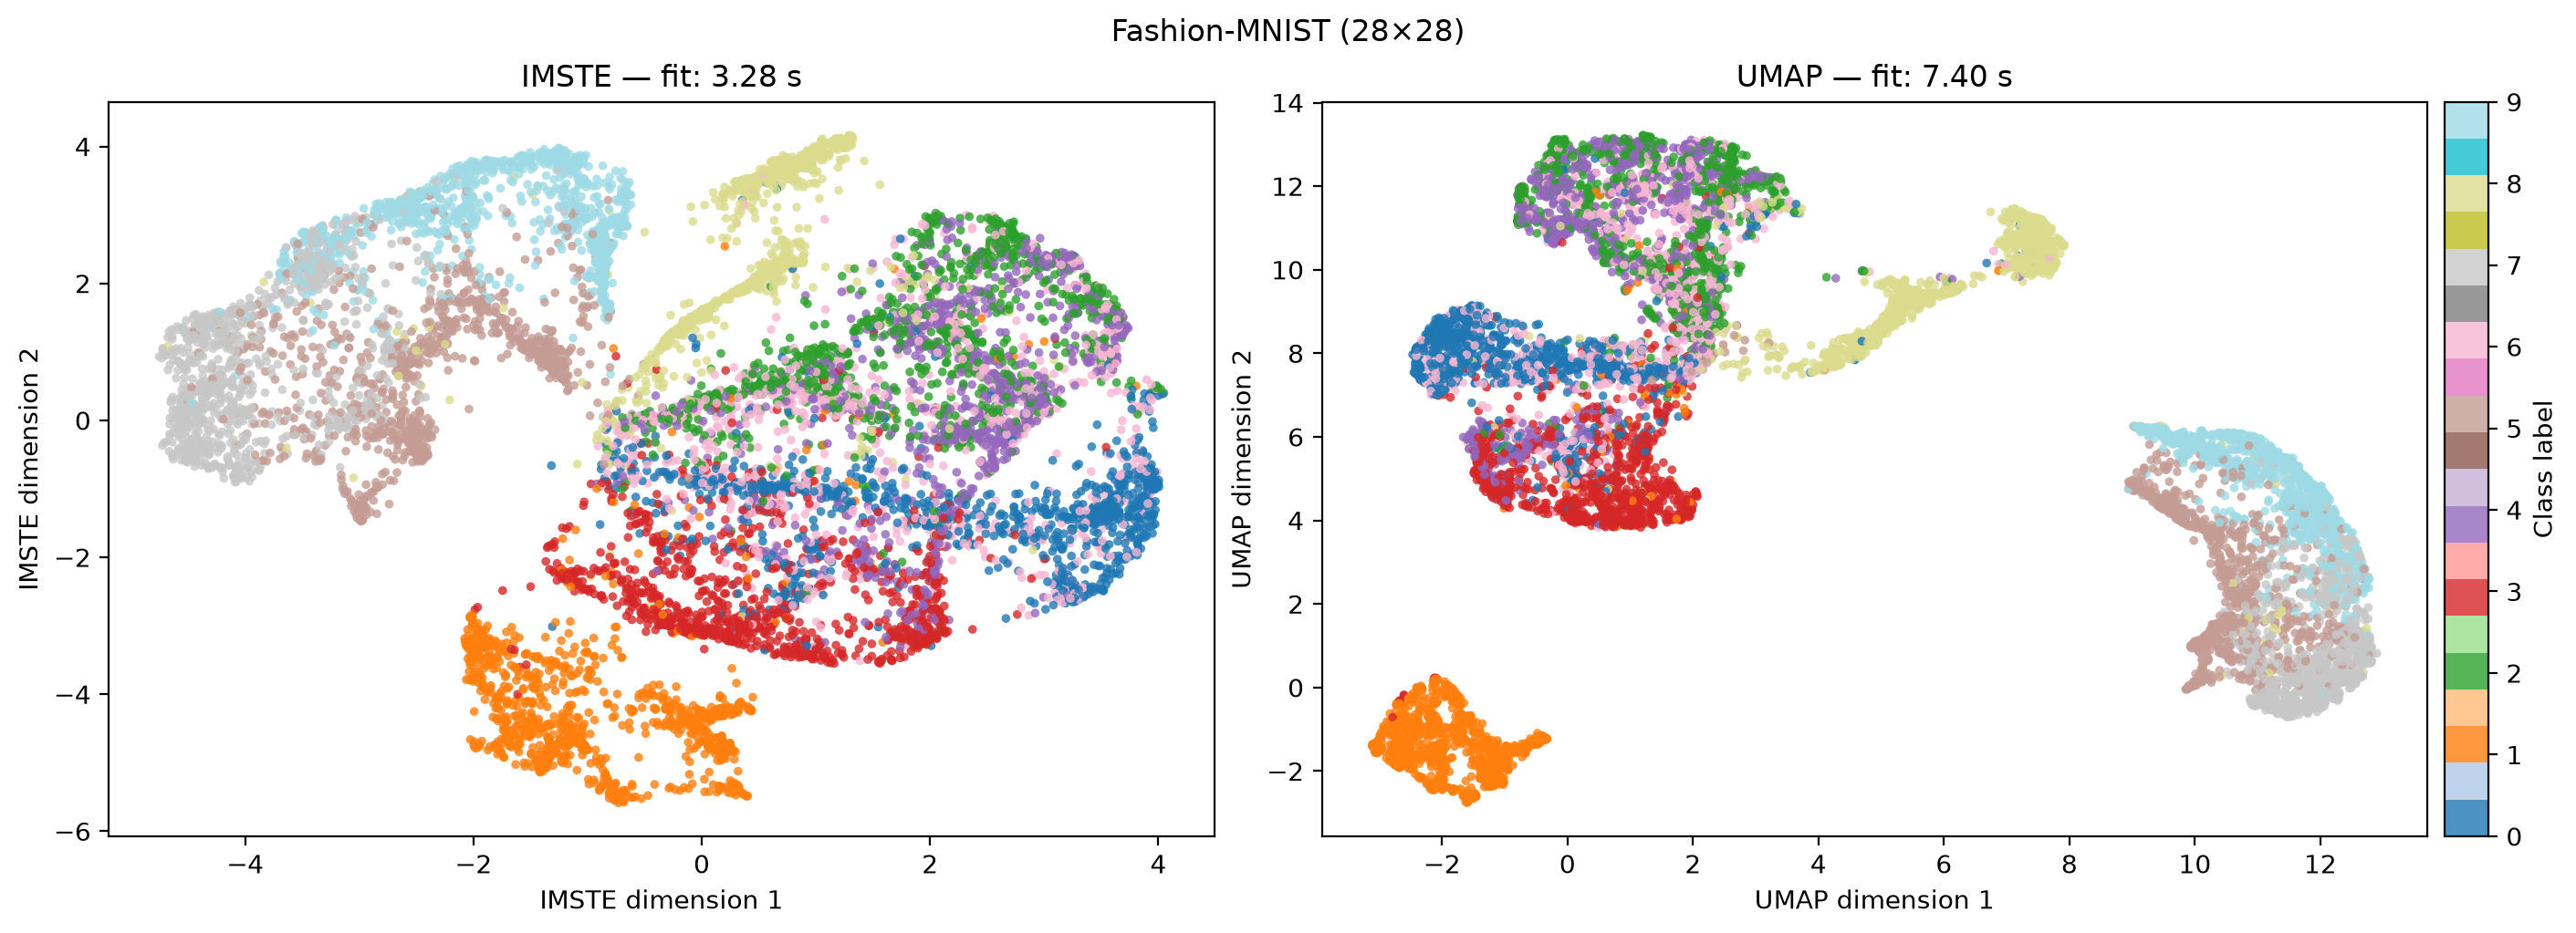

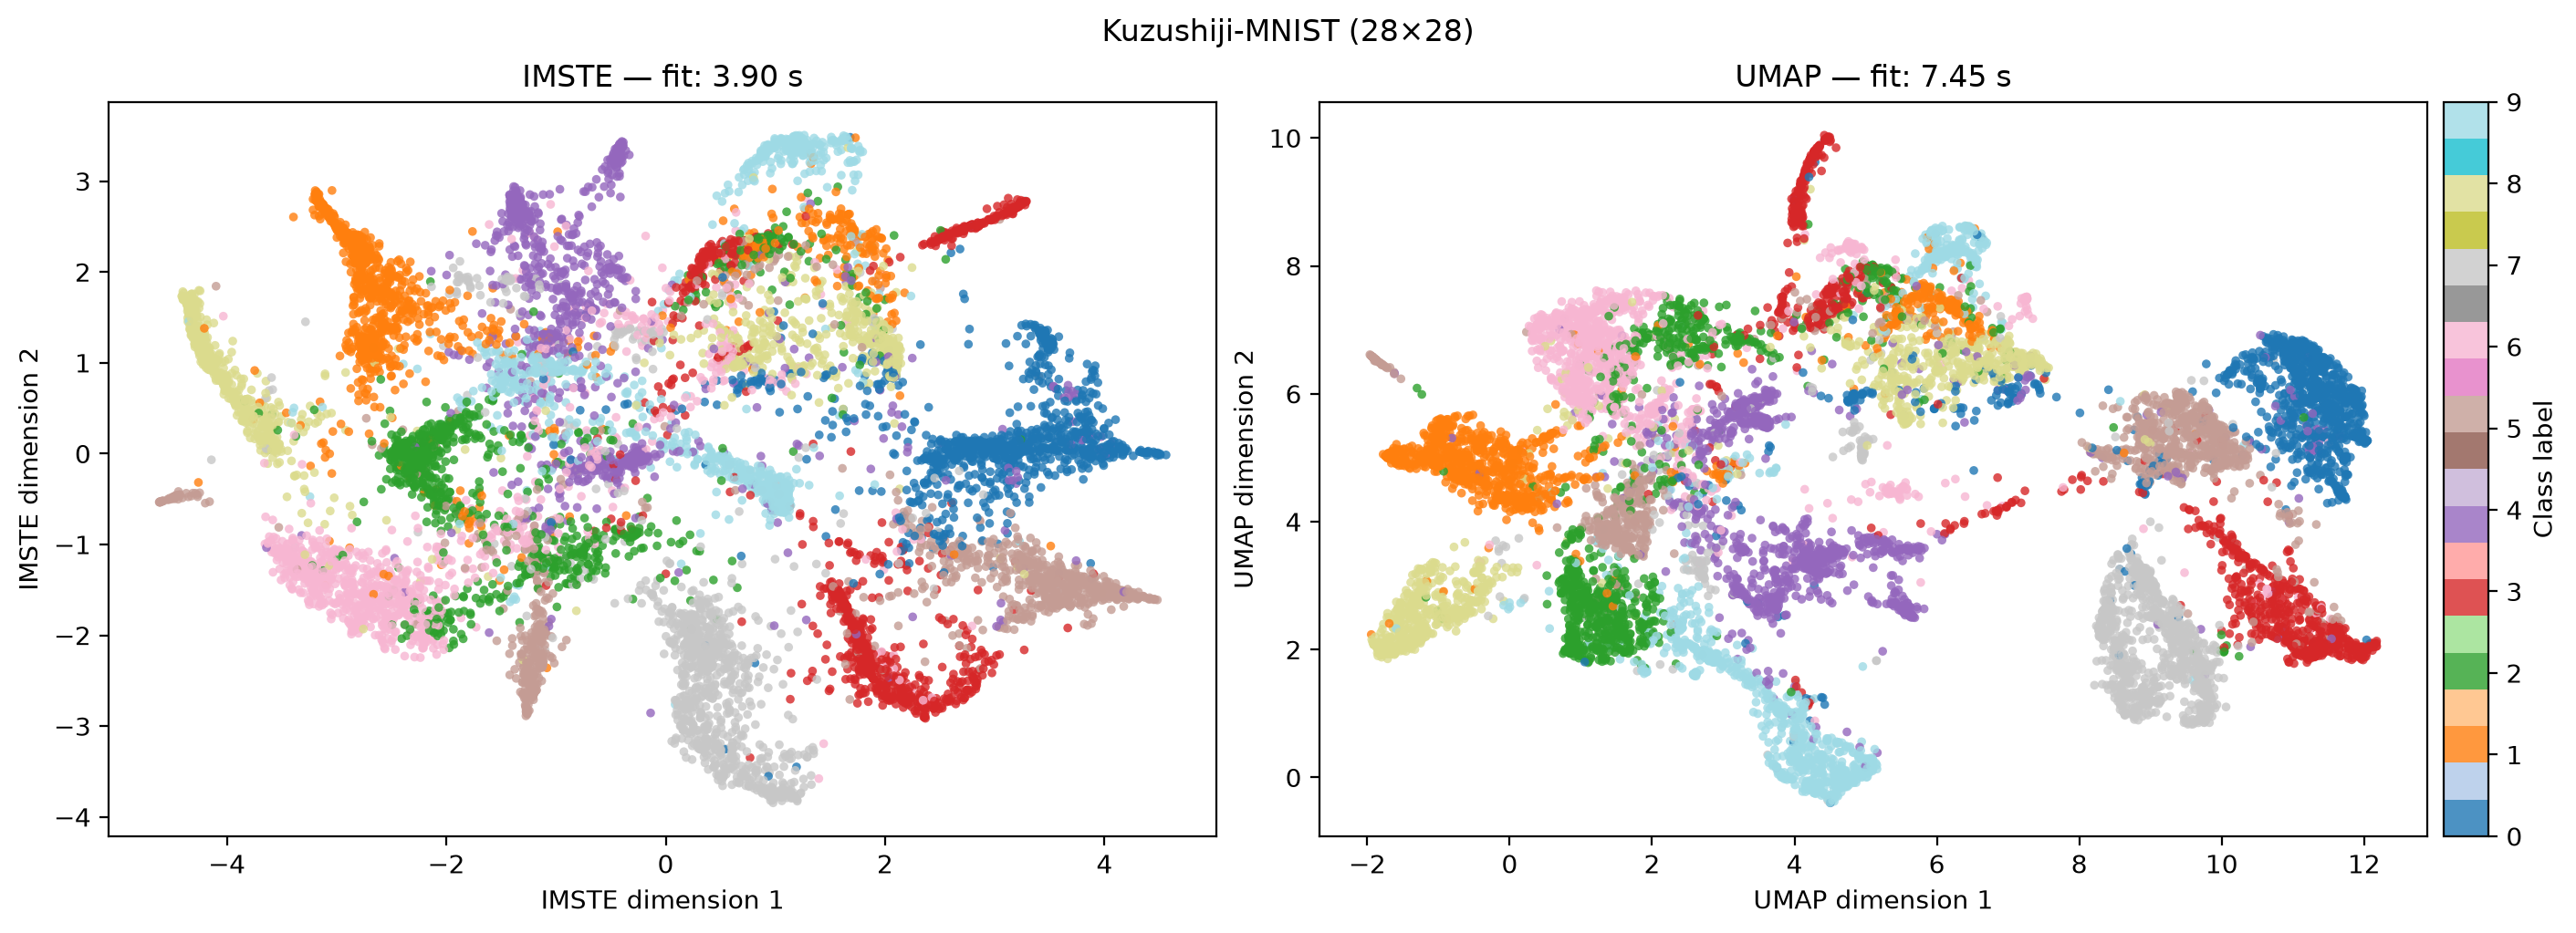

In [3]:
from time import perf_counter

import matplotlib.pyplot as plt
import numpy as np
import umap
from IPython.display import display
from sklearn.preprocessing import StandardScaler

UMAP_RESULTS = {}
IMSTE_SECONDS = gallery["summary"].set_index("dataset")["seconds"].to_dict()
for dataset_name, (raw_X, labels) in gallery["datasets"].items():
    X_standardized = StandardScaler().fit_transform(raw_X)
    started = perf_counter()
    umap_embedding = umap.UMAP(
        n_components=2, n_neighbors=15, min_dist=0.1,
        metric="euclidean", random_state=42, n_jobs=1,
    ).fit_transform(X_standardized)
    umap_seconds = perf_counter() - started
    UMAP_RESULTS[dataset_name] = umap_embedding

    imste_embedding = gallery["embeddings"][dataset_name]
    fig, (ax_imste, ax_umap, colorbar_axis) = plt.subplots(
        1, 3,
        figsize=(14, 5),
        gridspec_kw={"width_ratios": [1, 1, 0.04]},
        constrained_layout=True,
    )
    points = None
    for ax, embedding, method, elapsed in (
        (ax_imste, imste_embedding, "IMSTE", IMSTE_SECONDS[dataset_name]),
        (ax_umap, umap_embedding, "UMAP", umap_seconds),
    ):
        points = ax.scatter(
            embedding[:, 0], embedding[:, 1],
            c=labels, cmap="tab20", vmin=0, vmax=9,
            s=12, alpha=0.8, linewidths=0,
        )
        ax.set_title(f"{method} — fit: {elapsed:.2f} s")
        ax.set_xlabel(f"{method} dimension 1")
        ax.set_ylabel(f"{method} dimension 2")
    fig.suptitle(dataset_name)
    fig.colorbar(
        points,
        cax=colorbar_axis,
        label="Class label",
        ticks=np.unique(labels),
    )
    display(fig)
    plt.close(fig)


## Class-mixture graph overlay

The reusable plotting function in `imste.class_graph` fits up to three full-covariance Gaussian components per class in each 2D embedding. Each component mean becomes a node; node size reflects mixture weight and node color identifies its class. Two exact iterated MSTs are built over the nodes, then same-class edges are omitted. Remaining edges are black and match the node-outline width. Their opacity increases with symmetric cross-component probability: the two endpoint Gaussian densities form an equal-prior pairwise posterior, evaluated on the other component’s assigned samples in both directions. The directional probabilities are averaged; chance-level overlap (0.5) is fully opaque. All graph scores use the 2D embedding.

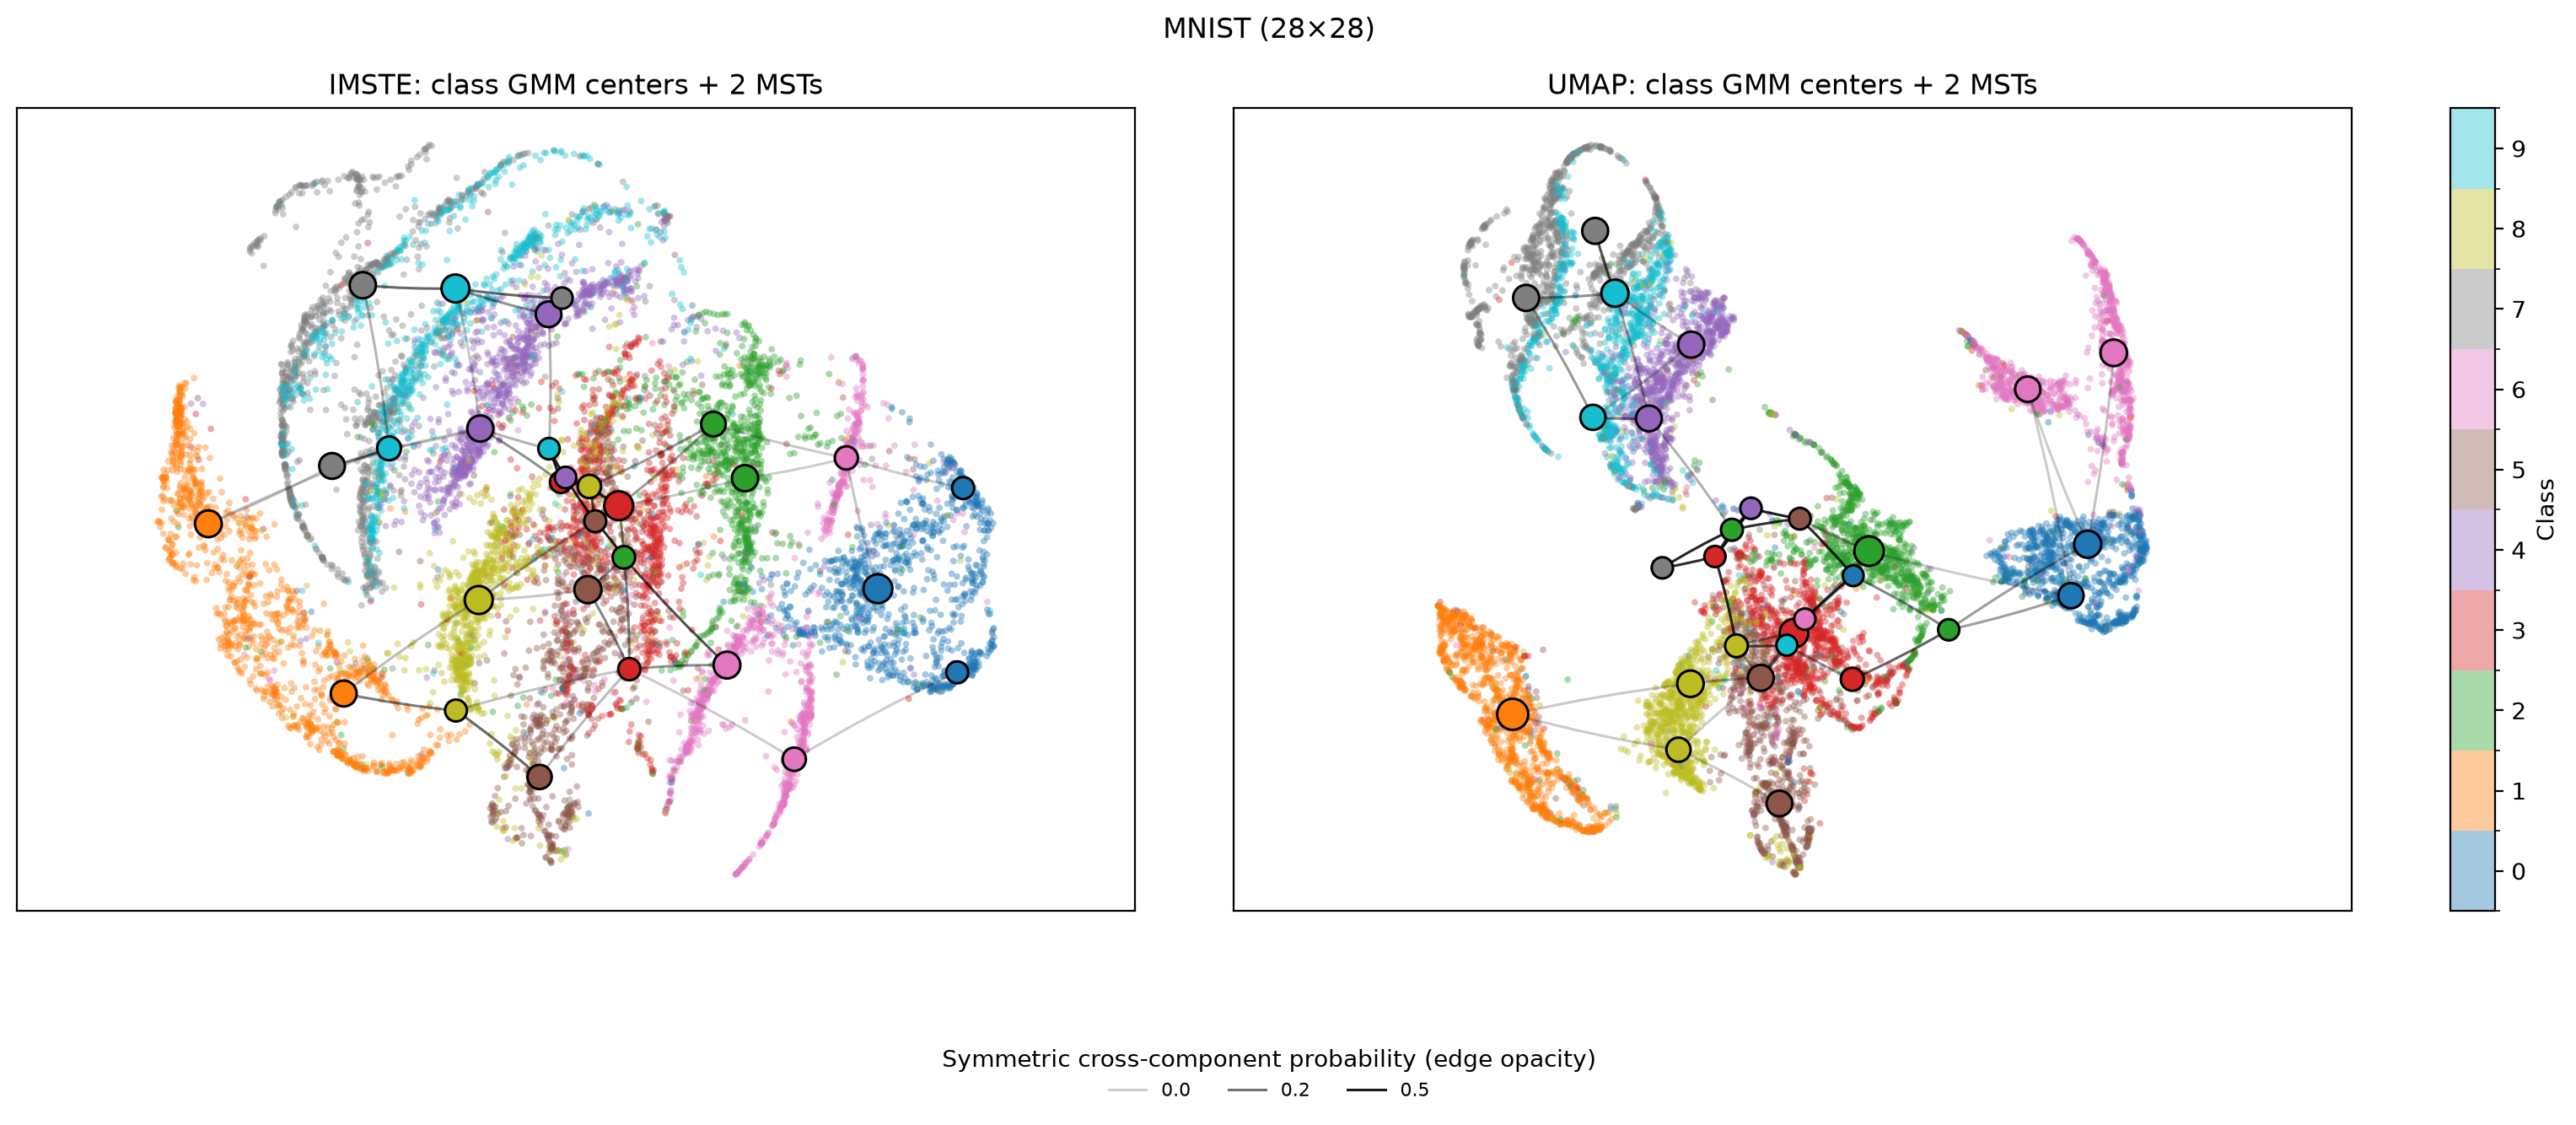

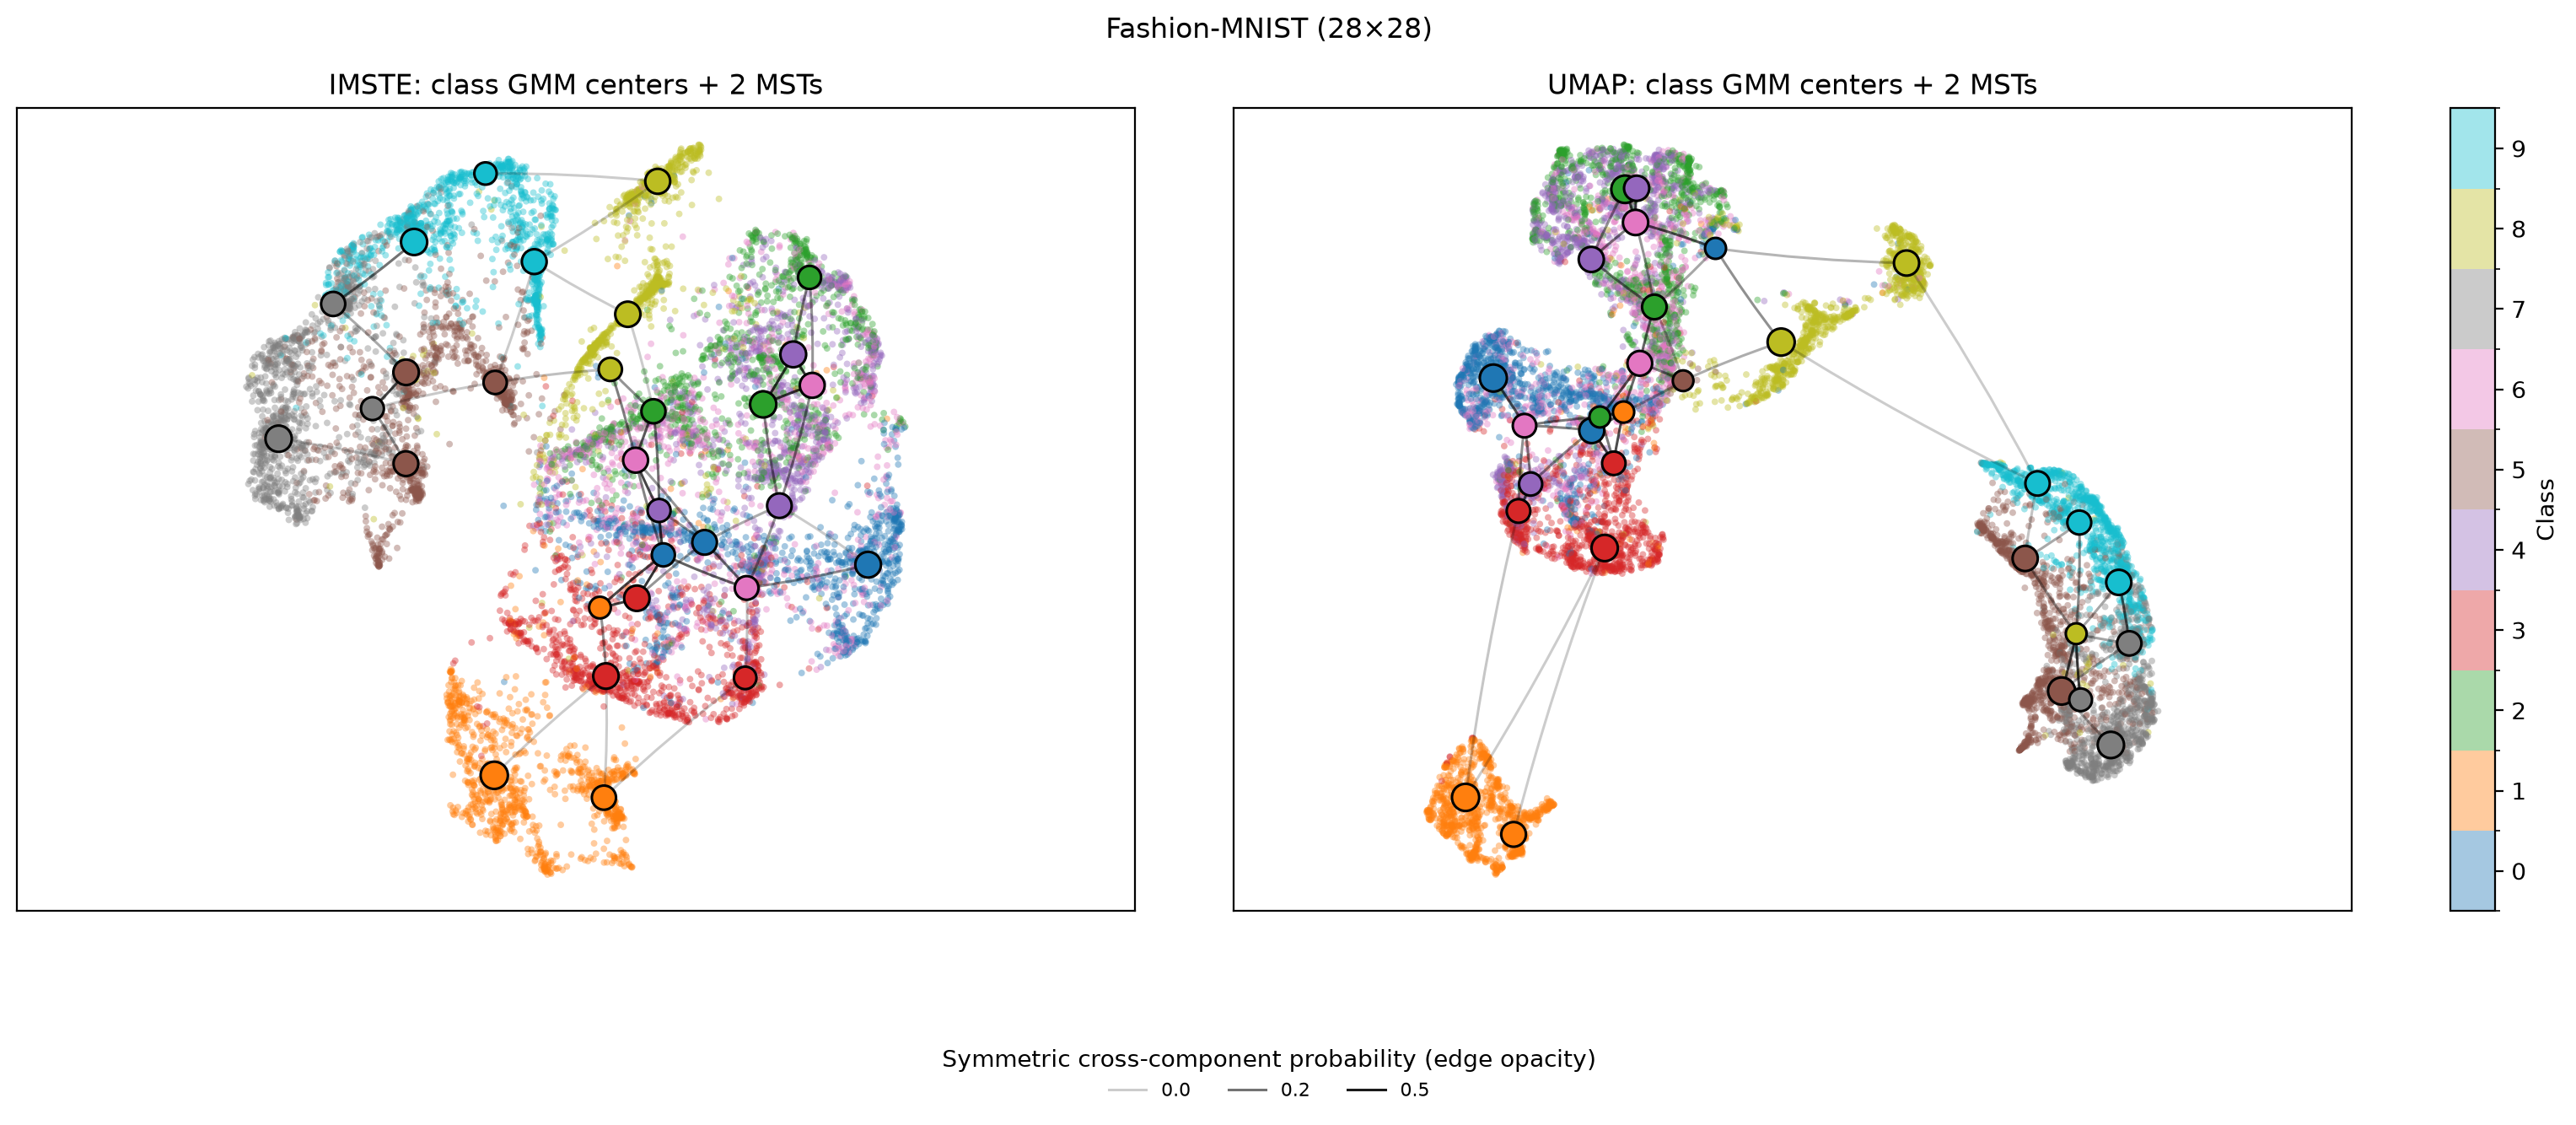

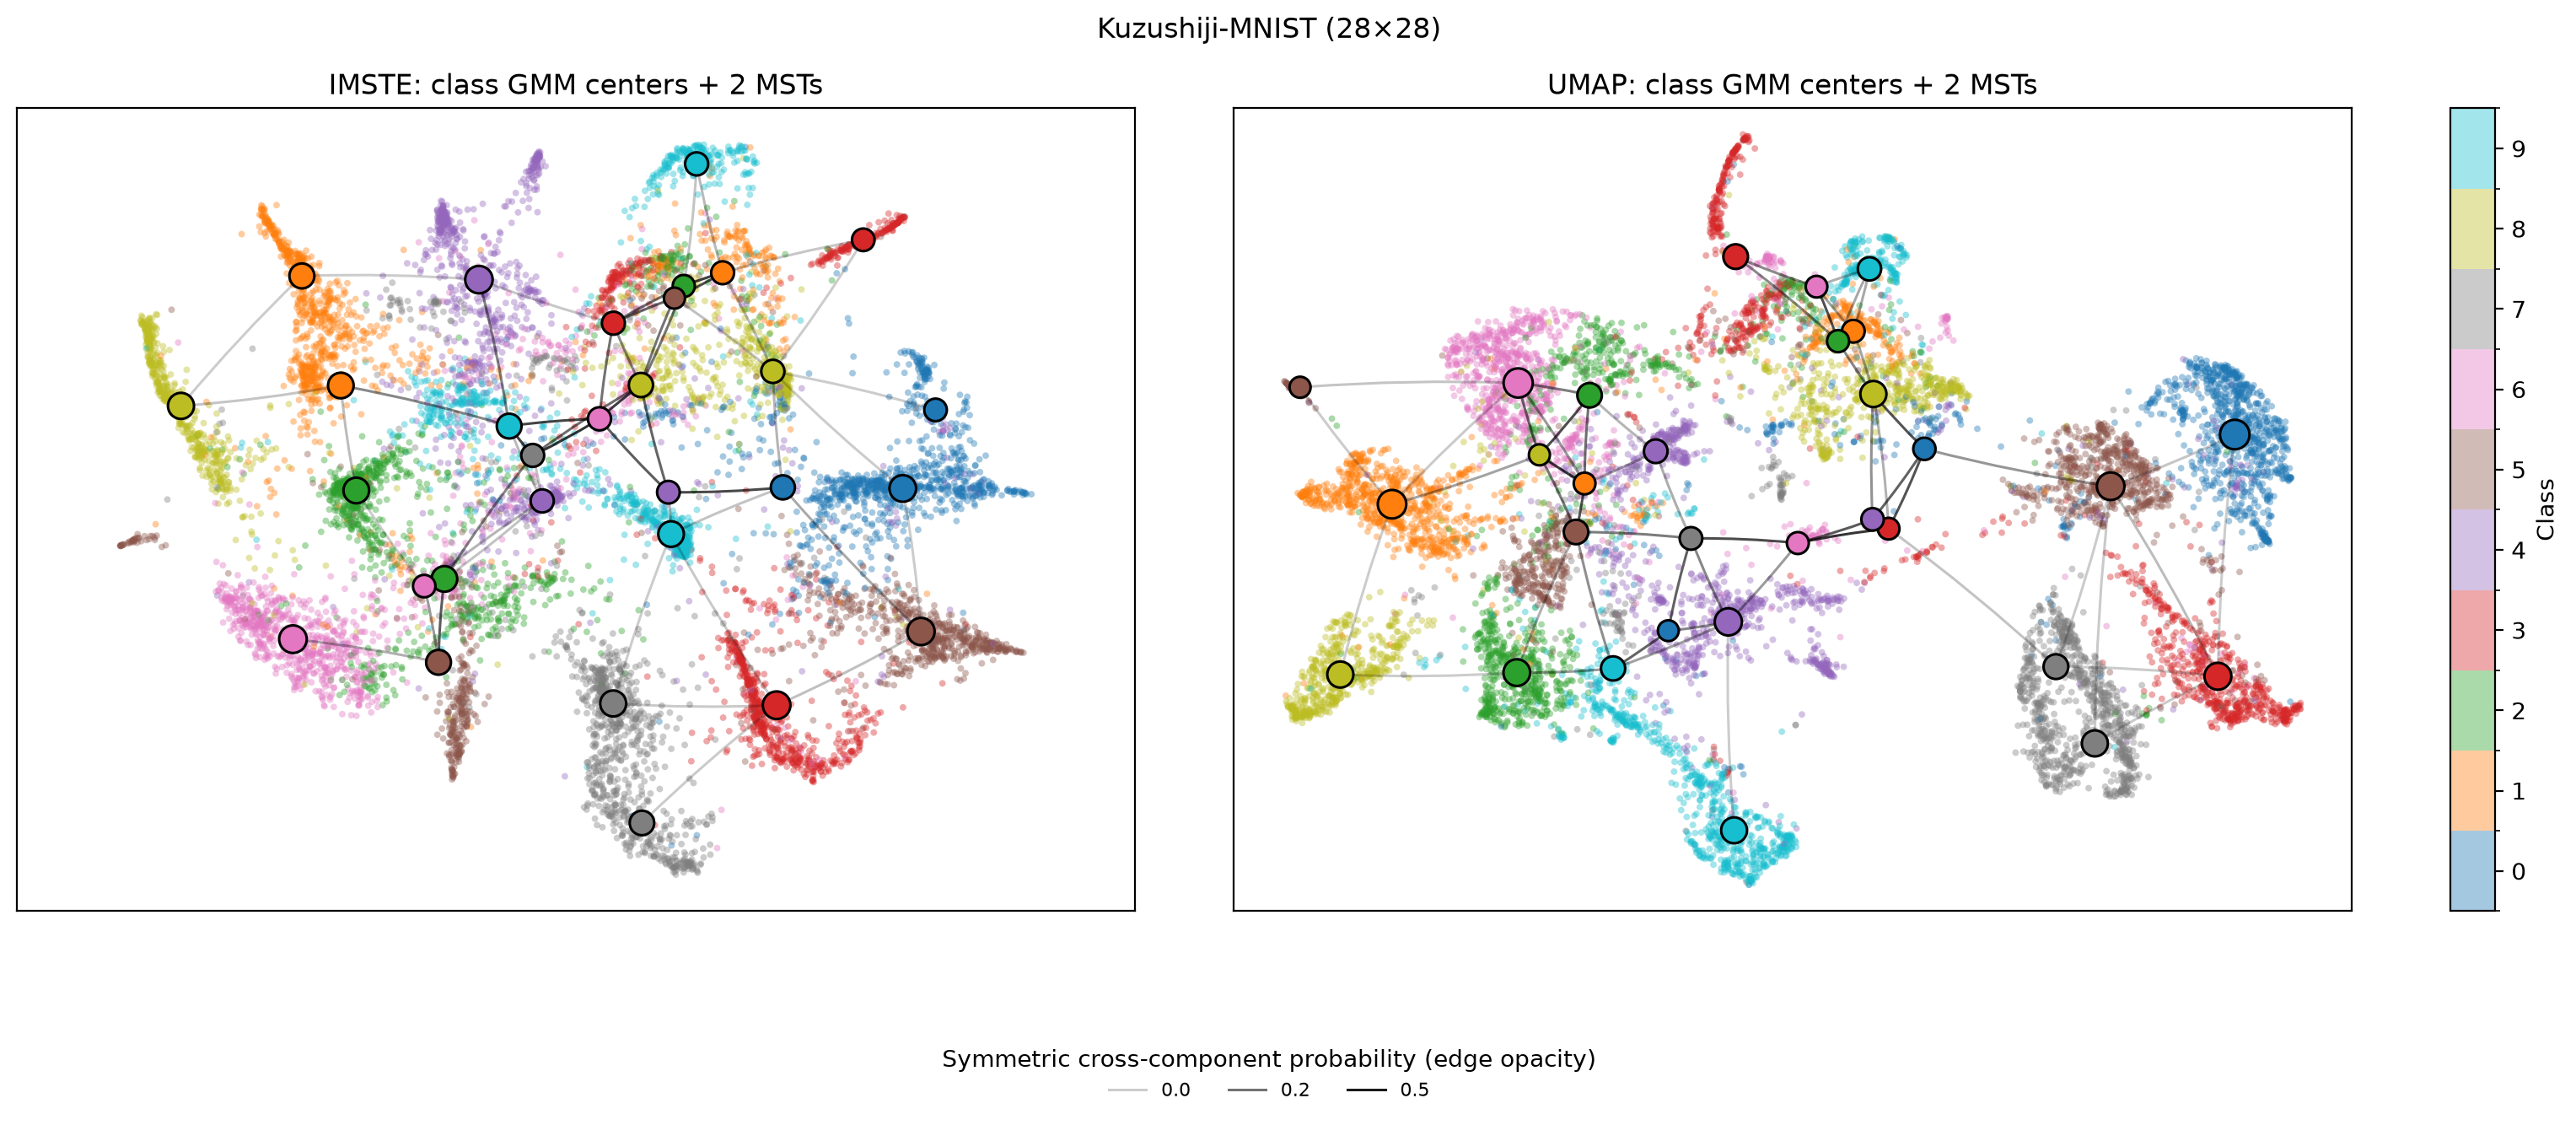

edges  mean_edge_alpha
dataset                 embedding                        
Fashion-MNIST (28×28)   IMSTE         43         0.449136
                        UMAP          48         0.490743
Kuzushiji-MNIST (28×28) IMSTE         52         0.405360
                        UMAP          56         0.429816
MNIST (28×28)           IMSTE         47         0.437486
                        UMAP          44         0.490223

In [4]:
import pandas as pd
from imste.class_graph import plot_class_mixture_mst

class_graph_edge_tables = []
for dataset_name, (raw_X, labels) in gallery["datasets"].items():
    fig, _, edge_scores = plot_class_mixture_mst(
        raw_X,
        labels,
        {
            "IMSTE": gallery["embeddings"][dataset_name],
            "UMAP": UMAP_RESULTS[dataset_name],
        },
        title=dataset_name,
        n_msts=2,
        max_components_per_class=3,
        point_alpha=0.4,
        min_edge_alpha=0.2,
        max_edge_alpha=0.9,
        random_state=42,
    )
    display(fig)
    plt.close(fig)
    edge_scores.insert(0, "dataset", dataset_name)
    class_graph_edge_tables.append(edge_scores)

class_graph_edges = pd.concat(class_graph_edge_tables, ignore_index=True)
class_graph_edges.groupby(["dataset", "embedding"]).agg(
    edges=("edge_alpha", "size"),
    mean_edge_alpha=("edge_alpha", "mean"),
)

## MNIST relations unique to each embedding

An edge connects two class-specific Gaussian components, so we collapse component edges to unordered digit pairs. The table lists pairs selected by the IMSTE MST but not the UMAP MST, and vice versa. It ranks each direction by mean edge error across distinct component edges: higher values mean the two endpoint Gaussians are harder to distinguish in that embedding. Component details and the maximum edge error are retained for inspection.

Use these as candidate relationships to interpret, not automatic evidence that a pair is semantically related. For example, a strong 4–9 relation is plausible because those digits can be visually confusable; check surprising pairs against digit examples or an independent MNIST confusion matrix. A missing edge only means that pair was not selected by that embedding’s MST.

In [5]:
from IPython.display import display
from imste.class_graph import compare_class_graph_relations

mnist_relation_differences = compare_class_graph_relations(
    class_graph_edges,
    method_a="IMSTE",
    method_b="UMAP",
    dataset="MNIST (28×28)",
)
display(mnist_relation_differences)

,rank,class_a,class_b,present_in,missing_from,edge_error,max_component_edge_error,n_component_edges,component_edges
0,1,4,8,IMSTE,UMAP,6.161834e-01,6.161834e-01,1,"((2, 2, 0.616183),)"
1,2,2,8,IMSTE,UMAP,2.716228e-01,2.716228e-01,1,"((2, 2, 0.271623),)"
2,3,4,7,IMSTE,UMAP,2.667942e-01,5.127436e-01,2,"((0, 0, 0.020845), (1, 2, 0.512744))"
3,4,1,7,IMSTE,UMAP,1.286361e-02,1.286361e-02,1,"((0, 0, 0.012864),)"
4,5,1,9,IMSTE,UMAP,2.076532e-09,2.076532e-09,1,"((0, 2, 0.0),)"
5,1,2,7,UMAP,IMSTE,9.355203e-01,9.355203e-01,1,"((1, 1, 0.93552),)"
6,2,0,5,UMAP,IMSTE,9.113643e-01,9.113643e-01,1,"((1, 2, 0.911364),)"
7,3,3,7,UMAP,IMSTE,8.834431e-01,8.834431e-01,1,"((2, 1, 0.883443),)"
8,4,6,9,UMAP,IMSTE,8.721156e-01,8.721156e-01,1,"((1, 2, 0.872116),)"
9,5,8,9,UMAP,IMSTE,6.302398e-01,6.302398e-01,1,"((1, 2, 0.63024),)"
